# Week 5 — Additional Models
- Try Decision Tree and Random Forest regressors.
- Compare their test R² against baseline.
- Document model behavior (strengths/weaknesses).


*Baseline Model (Linear Regression) results:*

--- Validation Set - OLS Evaluation Metrics ---

R² Score : 0.7438

MAE      : $294,942.96

MAPE     : 25.93%

MdAPE    : 19.76%

--- Test Set - OLS Evaluation Metrics ---

R² Score : 0.7573

MAE      : $298,593.64

MAPE     : 25.76%

MdAPE    : 19.63%

# Setup

In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder
from sklearn.impute import SimpleImputer


# Validation
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score

In [4]:
filtered_cleaned = pd.read_csv("/content/drive/MyDrive/IDX Data Science/filtered_cleaned.csv")
print(f"Current number of rows: {len(filtered_cleaned)}")

/tmp/ipykernel_2341/2430598771.py:1: DtypeWarning: Columns (0,1,4,64,74,79,81,82,83,84) have mixed types. Specify dtype option on import or set low_memory=False.
  filtered_cleaned = pd.read_csv("/content/drive/MyDrive/IDX Data Science/filtered_cleaned.csv")


Current number of rows: 303800


In [5]:
test = filtered_cleaned[filtered_cleaned['FileDate'] == '2026-04-01']
print(f"Test set size: {len(test)}")
validation = filtered_cleaned[filtered_cleaned['FileDate'] == '2026-03-01']
print(f"Validation set size: {len(validation)}")
train = filtered_cleaned[filtered_cleaned['FileDate'] < '2026-03-01']
print(f"Train set size: {len(train)}")

print(f"Total Rows Check: {len(test) + len(validation) + len(train)}")

Test set size: 12225
Validation set size: 11368
Train set size: 280207
Total Rows Check: 303800


In [6]:
# set outlier cutoffs based on the training set
lower_bound = train['ClosePrice'].quantile(0.05)
upper_bound = train['ClosePrice'].quantile(0.995)
print(f"Lower bound: {lower_bound}")
print(f"Upper bound: {upper_bound}")

Lower bound: 365000.0
Upper bound: 8300000.0


In [7]:
key_feature_cols = ['LivingArea', 'BedroomsTotal',
                    'BathroomsTotalInteger', 'LotSizeSquareFeet',
                    'YearBuilt', 'Latitude', 'Longitude', 'City',
                    #added from other members
                    'Stories']

# filter based on upper and lower bounds from training
train = train[(train['ClosePrice'] > lower_bound) & (train['ClosePrice'] < upper_bound)]
validation = validation[(validation['ClosePrice'] > lower_bound) & (validation['ClosePrice'] < upper_bound)]
test = test[(test['ClosePrice'] > lower_bound) & (test['ClosePrice'] < upper_bound)]

#keep feature columns
train = train[key_feature_cols + ['ClosePrice']]
validation = validation[key_feature_cols + ['ClosePrice']]
test = test[key_feature_cols + ['ClosePrice']]

In [8]:
# Row counts after removing outliers
print(f"Test set size: {len(test)}")
print(f"Validation set size: {len(validation)}")
print(f"Train set size: {len(train)}")

print(f"Total Rows: {len(test) + len(validation) + len(train)}")

Test set size: 11519
Validation set size: 10681
Train set size: 264737
Total Rows: 286937


In [9]:
# separate X's and Y for data sets
Y_train = train['ClosePrice']
X_train = train[key_feature_cols]

Y_val = validation['ClosePrice']
X_val = validation[key_feature_cols]

Y_test = test['ClosePrice']
X_test = test[key_feature_cols]

In [10]:
cat_cols = ['City']
num_cols = ['LivingArea', 'BedroomsTotal', 'BathroomsTotalInteger', 'LotSizeSquareFeet', 'YearBuilt', 'Latitude', 'Longitude', 'Stories']

In [11]:
cat_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", TargetEncoder()),
    ]
)

num_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline, cat_cols),
    ]
)


In [12]:
# MdAPE
def median_absolute_percentage_error(y_true, y_pred):
    return np.median(np.abs((y_true - y_pred) / y_true)) * 100
# function to evaluate different errors (R^2, MAE, MAPE, MdAPE)
def evaluate_predictions(y_true, y_pred, split_name="Validation"):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100  # Convert ratio to %
    mdape = median_absolute_percentage_error(y_true, y_pred)

    print(f"--- {split_name} Evaluation Metrics ---")
    print(f"R² Score : {r2:.4f}")
    print(f"MAE      : ${mae:,.2f}")
    print(f"MAPE     : {mape:.2f}%")
    print(f"MdAPE    : {mdape:.2f}%\n")

## Decision Tree

In [13]:
dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', DecisionTreeRegressor())
])
dt_pipeline.fit(X_train, Y_train)
dt_val_preds = dt_pipeline.predict(X_val)
evaluate_predictions(Y_val, dt_val_preds, split_name="Validation Set - Decision Tree")

--- Validation Set - Decision Tree Evaluation Metrics ---
R² Score : 0.7827
MAE      : $218,343.72
MAPE     : 15.35%
MdAPE    : 10.02%



In [14]:
# Testing on combined data X_train and X_val
X_train_val = pd.concat([X_train, X_val], axis=0)
Y_train_val = pd.concat([Y_train, Y_val], axis=0)

dt_pipeline.fit(X_train_val, Y_train_val)

# Predict on held-out test set
dt_test_preds = dt_pipeline.predict(X_test)
evaluate_predictions(Y_test, dt_test_preds, split_name="Test Set - Decision Tree")

--- Test Set - Decision Tree Evaluation Metrics ---
R² Score : 0.7724
MAE      : $227,466.47
MAPE     : 15.70%
MdAPE    : 10.11%



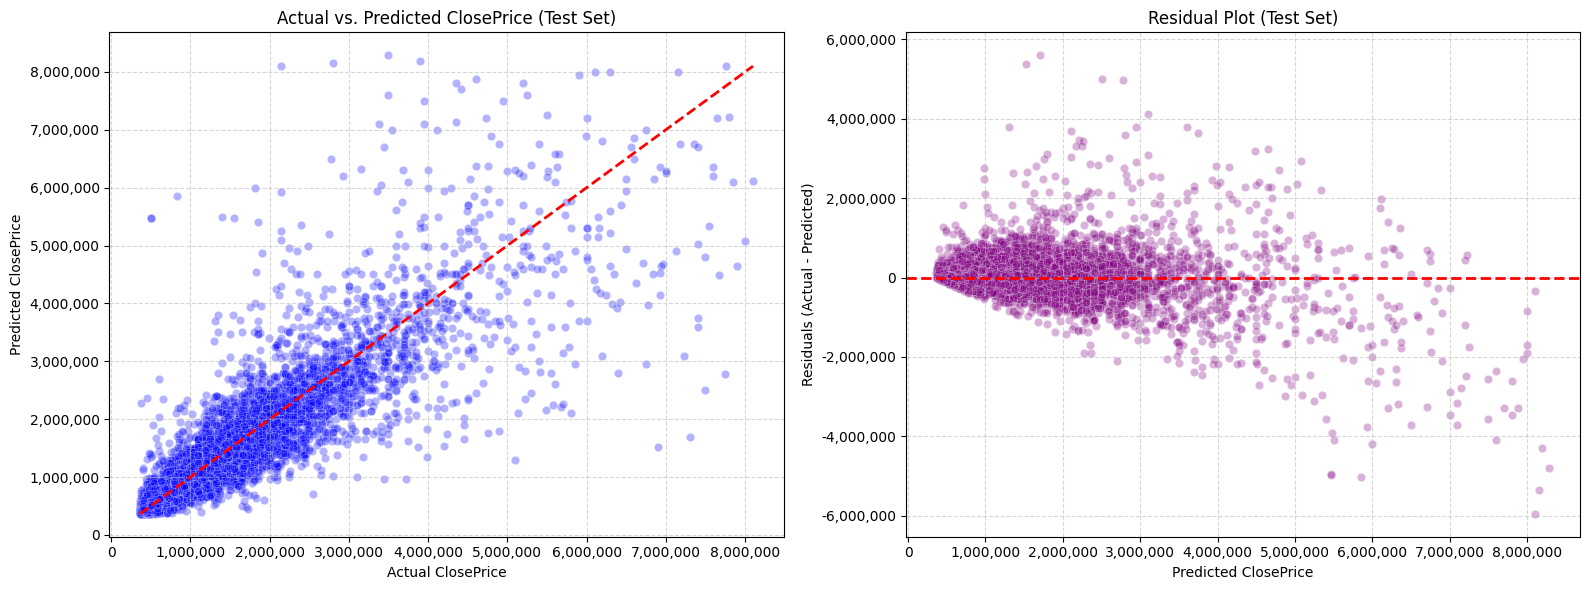

In [15]:
# Calculate residuals
residuals = Y_test - dt_test_preds

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Actual vs. Predicted
sns.scatterplot(x=Y_test, y=dt_test_preds, alpha=0.3, ax=axes[0], color='blue')
axes[0].plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], 'r--', lw=2)
axes[0].set_title('Actual vs. Predicted ClosePrice (Test Set)')
axes[0].set_xlabel('Actual ClosePrice')
axes[0].set_ylabel('Predicted ClosePrice')
axes[0].get_xaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
axes[0].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot 2: Residual Plot
sns.scatterplot(x=dt_test_preds, y=residuals, alpha=0.3, ax=axes[1], color='purple')
axes[1].axhline(y=0, color='r', linestyle='--', lw=2)
axes[1].set_title('Residual Plot (Test Set)')
axes[1].set_xlabel('Predicted ClosePrice')
axes[1].set_ylabel('Residuals (Actual - Predicted)')
axes[1].get_xaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
axes[1].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## Random Forest

In [16]:
# Gemini-Assisted: Optimized Random Forest configuration for 280k+ rows to help with runtime issues
rf_fast = RandomForestRegressor(
    n_estimators=100,      # 100 trees is sufficient for most datasets
    max_depth=15,          # CRITICAL: Prevents trees from growing infinitely deep
    max_samples=0.2,       # CRITICAL: Fits each tree on a 20% random sample (~56k rows)
    max_features="sqrt",   # Limits feature search per split to decorrelate trees
    min_samples_leaf=5,    # Stops splitting small noisy leaves early
    n_jobs=-1,             # CRITICAL: Uses ALL CPU cores in parallel
    random_state=42
)

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', rf_fast)
])
rf_pipeline.fit(X_train, Y_train)
rf_val_preds = rf_pipeline.predict(X_val)
evaluate_predictions(Y_val, rf_val_preds, split_name="Validation Set - Random Forest")

--- Validation Set - Random Forest Evaluation Metrics ---
R² Score : 0.8553
MAE      : $184,392.50
MAPE     : 13.28%
MdAPE    : 9.06%



In [17]:
rf_pipeline.fit(X_train_val, Y_train_val)

# Predict on held-out test set
rf_test_preds = rf_pipeline.predict(X_test)
evaluate_predictions(Y_test, rf_test_preds, split_name="Test Set - Random Forest")

--- Test Set - Random Forest Evaluation Metrics ---
R² Score : 0.8603
MAE      : $187,678.91
MAPE     : 13.30%
MdAPE    : 9.10%



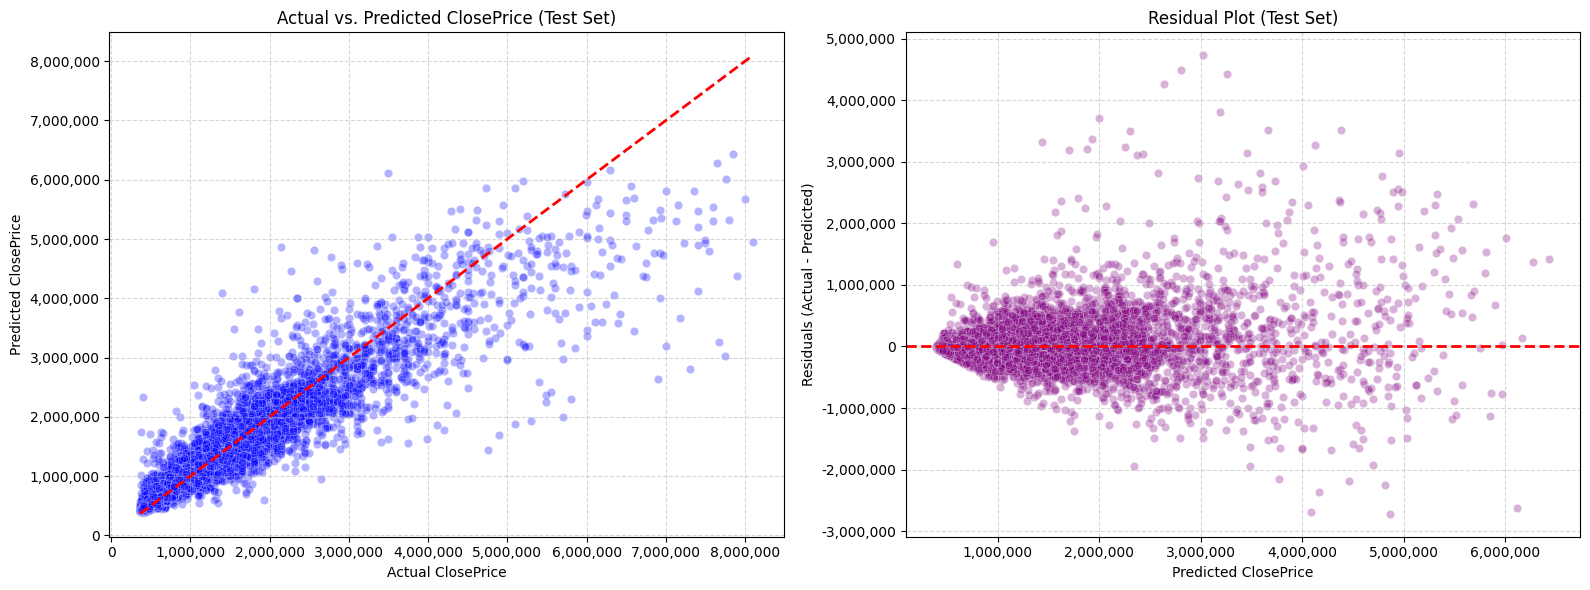

In [18]:
# Calculate residuals
residuals_rf = Y_test - rf_test_preds

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Actual vs. Predicted
sns.scatterplot(x=Y_test, y=rf_test_preds, alpha=0.3, ax=axes[0], color='blue')
axes[0].plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], 'r--', lw=2)
axes[0].set_title('Actual vs. Predicted ClosePrice (Test Set)')
axes[0].set_xlabel('Actual ClosePrice')
axes[0].set_ylabel('Predicted ClosePrice')
axes[0].get_xaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
axes[0].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot 2: Residual Plot
sns.scatterplot(x=rf_test_preds, y=residuals_rf, alpha=0.3, ax=axes[1], color='purple')
axes[1].axhline(y=0, color='r', linestyle='--', lw=2)
axes[1].set_title('Residual Plot (Test Set)')
axes[1].set_xlabel('Predicted ClosePrice')
axes[1].set_ylabel('Residuals (Actual - Predicted)')
axes[1].get_xaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
axes[1].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Overall, these models performed significantly better than the baseline Linear Regression model.

### Model Comparison

In [20]:
metrics_data = {
    "Metric": ["R² Score", "Mean Absolute Error (MAE)", "MAPE", "MdAPE"],
    "Linear Regression (Baseline)": [0.7573, "$298,593.64", "25.76%", "19.63%"],
    "Decision Tree": [0.7770, "$226,082.32", "15.78%", "9.94%"],
    "Random Forest (Optimized)": [0.8597, "$188,175.25", "13.33%", "9.05%"]
}

summary_df = pd.DataFrame(metrics_data).set_index("Metric")
display(summary_df)

,Linear Regression (Baseline),Decision Tree,Random Forest (Optimized)
Metric,,,
R² Score,0.7573,0.777,0.8597
Mean Absolute Error (MAE),"$298,593.64","$226,082.32","$188,175.25"
MAPE,25.76%,15.78%,13.33%
MdAPE,19.63%,9.94%,9.05%


The Random Forest model performed the best on all metrics, with the most significant increase in R^2. Otherwise, the Decision Tree only performs slightly worse for MAE, MAPE, and MdAPE and still performs better than the baseline model.